In [ ]:

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint as sp_randint

In [ ]:
# Modelado y métricas
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression # Importacion para modelo multinomial
from sklearn.tree import DecisionTreeClassifier, plot_tree #Importacion para modelo de arboles de desicion
from sklearn.ensemble import RandomForestClassifier#Importacion para modelo de arboles aleatorios
from sklearn.cluster import KMeans
from sklearn.svm import SVC # La clase para SVM de clasificación # modelo de soporte vectorial
from sklearn.metrics import precision_score, recall_score, f1_score,accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [ ]:

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, LabelBinarizer

# Técnicas de balanceo (imblearn)
from imblearn.over_sampling import  SMOTE


In [ ]:

# Utilidades
import warnings
warnings.filterwarnings('ignore')


In [ ]:
#Escalamiento y Metricas
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import log_loss
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Carga del archivo csv

files = files.upload()

Saving AI_SocialMedia_Student_Health_Dataset_clean (1).csv to AI_SocialMedia_Student_Health_Dataset_clean (1).csv


In [ ]:
# Convertimos el archivo en un dataframe

data = pd.read_csv('AI_SocialMedia_Student_Health_Dataset_clean (1).csv')

#Contexto

En la actualidad el agotamiento de los jovenes se ha visto gravemente afectado debido a la realidad moderna donde se ven constantemente inmersos en altos grados de uso de redes sociales y herramientas de IA en sus contextos, todo esto llevando a un grave deterioro de sus rendimientos academicos. Por lo consiguiente nace la necesidad de dar respuesta a que variables son las inciden en este problema.


Se requiere predecir la posibilidad de fracaso academico de acuerdo al comportamiento de variables clave como hora de sueño, uso de redes sociales y herramientas de ia, actividad fisica entre otras. con el objectivo de determinar las causales con mayor incidencia

In [ ]:
data.shape

(15000, 14)

In [ ]:
data.head()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score,Burnout_Level,Academic_Performance_Score,Academic_Failure_Risk
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,4.05,Low,88.80,0
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,4.65,Moderate,50.60,0
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,5.28,Low,96.67,0
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,3.66,Low,85.65,0
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,3.25,Moderate,71.84,0


In [ ]:
data.tail()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score,Burnout_Level,Academic_Performance_Score,Academic_Failure_Risk
14995,STU_14996,18,Non-binary,College,6.10,0.72,5.63,0.89,74.08,71.92,3.78,Moderate,77.43,0
14996,STU_14997,22,Female,University,4.55,1.20,7.20,0.00,73.72,85.84,5.06,Low,75.81,0
14997,STU_14998,13,Male,High School,7.83,1.46,6.22,0.64,70.03,86.62,4.76,Moderate,89.84,0
14998,STU_14999,20,Female,College,6.99,3.00,4.24,1.97,57.38,85.34,2.82,Severe,65.44,1
14999,STU_15000,14,Male,High School,3.73,3.03,6.39,1.50,71.69,78.62,4.37,Moderate,92.91,0


#Exploración Inicial y Estructura del DataFrame
Permite identificar cantidad de registros, columnas, tipos de datos y posibles valores nulos

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  15000 non-null  object 
 1   Age                         15000 non-null  int64  
 2   Gender                      15000 non-null  object 
 3   Education_Level             15000 non-null  object 
 4   Daily_Social_Media_Hours    15000 non-null  float64
 5   Daily_AI_Tool_Usage_Hours   15000 non-null  float64
 6   Sleep_Hours                 15000 non-null  float64
 7   Physical_Activity_Hours     15000 non-null  float64
 8   Mental_Health_Score         15000 non-null  float64
 9   Physical_Health_Score       15000 non-null  float64
 10  Social_Isolation_Score      15000 non-null  float64
 11  Burnout_Level               15000 non-null  object 
 12  Academic_Performance_Score  15000 non-null  float64
 13  Academic_Failure_Risk       150

#Métricas Descriptivas

In [ ]:
#Genera estadísticas descriptivas completas para todas las columnas
data.describe(include='all')

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score,Burnout_Level,Academic_Performance_Score,Academic_Failure_Risk
count,15000,15000.000000,15000,15000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000,15000.000000,15000.000000
unique,15000,NaN,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN
top,STU_15000,NaN,Male,High School,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,NaN,NaN
freq,1,NaN,7265,5693,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9000,NaN,NaN
mean,NaN,19.040667,NaN,NaN,4.537500,2.584580,6.544205,1.246332,72.513156,88.019761,4.312027,NaN,78.314859,0.060000
std,NaN,3.767257,NaN,NaN,2.398494,1.677988,1.269770,1.038349,9.245482,9.684253,1.162432,NaN,11.544651,0.237495
min,NaN,13.000000,NaN,NaN,0.000000,0.000000,2.000000,0.000000,32.560000,48.030000,0.970000,NaN,23.990000,0.000000
25%,NaN,16.000000,NaN,NaN,2.830000,1.310000,5.680000,0.310000,66.780000,81.520000,3.470000,NaN,70.530000,0.000000
50%,NaN,19.000000,NaN,NaN,4.500000,2.510000,6.550000,1.130000,73.760000,89.470000,4.280000,NaN,78.590000,0.000000
75%,NaN,22.000000,NaN,NaN,6.180000,3.740000,7.410000,1.950000,79.580000,97.160000,5.120000,NaN,86.700000,0.000000


#Tipos de datos

In [ ]:
data.dtypes

,0
Student_ID,object
Age,int64
Gender,object
Education_Level,object
Daily_Social_Media_Hours,float64
Daily_AI_Tool_Usage_Hours,float64
Sleep_Hours,float64
Physical_Activity_Hours,float64
Mental_Health_Score,float64
Physical_Health_Score,float64


Con el resultado dado de los tipos de datos se identifican a los tipo object que se cambiaran posteriomente a category, los demas datos conservaran su tipo actual.

#Verificar de valores nulos

In [ ]:
# 4.Datos nulos
data.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Education_Level,0
Daily_Social_Media_Hours,0
Daily_AI_Tool_Usage_Hours,0
Sleep_Hours,0
Physical_Activity_Hours,0
Mental_Health_Score,0
Physical_Health_Score,0


El dataset no contiene datos nulos, por lo que no es necesario hacer una imputación de datos faltantes

#Verificar datos duplicados

In [ ]:
data.duplicated().sum()

np.int64(0)

El dataset no contiene datos duplicados, por lo que no hay nada que eliminar

#Verificar datos ceros

In [ ]:
#6.Determinar que columnas del dataset tienen datos con valor cero

columnas_con_ceros = data.columns[(data == 0).any()]

# Hace un conteo de cuantos valores ceros tiene cada columna

for columna in columnas_con_ceros:
    conteo_ceros = (data[columna] == 0).sum()
    print(f"Columna - {columna}: {conteo_ceros} ceros")

Columna - Daily_Social_Media_Hours: 533 ceros
Columna - Daily_AI_Tool_Usage_Hours: 1240 ceros
Columna - Physical_Activity_Hours: 2639 ceros
Columna - Academic_Failure_Risk: 14100 ceros


Los datos ceros en estas columnas son normales, ya que en un valor de 0 en las columnas Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours y Physical_Activity_Hours simplemente significa que el estudiante no dedicó tiempo a esas actividades durante el período medido. En la columna Academic_Failure_Risk es una variable categórica donde 0 indica 'No riesgo de fracaso académico' y 1 indica 'Si riesgo de fracaso académico'

#Verificar datos negativos

In [ ]:
data.select_dtypes(include=['int64', 'float64']).lt(0).sum()

,0
Age,0
Daily_Social_Media_Hours,0
Daily_AI_Tool_Usage_Hours,0
Sleep_Hours,0
Physical_Activity_Hours,0
Mental_Health_Score,0
Physical_Health_Score,0
Social_Isolation_Score,0
Academic_Performance_Score,0
Academic_Failure_Risk,0


Ninguna de las columnas del dataframe cuenta con datos negativos, por lo cual no se generan cambios

#Renobramiento de variables del ingles al español

In [ ]:
data.columns=['ID_Estudiante','Edad','Genero','Nivel_Educacion','Horas_Uso_Redes_Sociales_Diarias',
              'Horas_Uso_Herramientas_IA_Diarias','Horas_Sueño','Horas_Actividad_Fisica',
              'Puntuacion_Salud_Mental','Puntuacion_Salud_Fisica','Puntuacion_Aislamiento_Social',
              'Nivel_Agotamiento','Puntuacion_Rendimiento_Academico','Riesgo_Fracaso_Academico']
display(data.head())

,ID_Estudiante,Edad,Genero,Nivel_Educacion,Horas_Uso_Redes_Sociales_Diarias,Horas_Uso_Herramientas_IA_Diarias,Horas_Sueño,Horas_Actividad_Fisica,Puntuacion_Salud_Mental,Puntuacion_Salud_Fisica,Puntuacion_Aislamiento_Social,Nivel_Agotamiento,Puntuacion_Rendimiento_Academico,Riesgo_Fracaso_Academico
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,4.05,Low,88.80,0
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,4.65,Moderate,50.60,0
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,5.28,Low,96.67,0
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,3.66,Low,85.65,0
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,3.25,Moderate,71.84,0


Todas la variables fueron renombradas a su equivalente en español para una mejorar el analisis posterior.

#Correcion de errores tipograficos

In [ ]:
col_cat = ['Genero', 'Nivel_Educacion', 'Nivel_Agotamiento']
#Aqui vericamos que columnas categoricas poseen errores tipograficos
for col in col_cat:
    print(data[col].value_counts())
    print('----')

Genero
Male          7265
Female        7143
Non-binary     592
Name: count, dtype: int64
----
Nivel_Educacion
High School    5693
University     4710
College        4597
Name: count, dtype: int64
----
Nivel_Agotamiento
Low         9000
Moderate    4200
High        1350
Severe       450
Name: count, dtype: int64
----


las variables categoricas no presentan errores de escritura, por lo que se dejaran las categorias de la forma como ya estan escritas.

#Categorizacion de las variables tipo object / codificacion de las categoricas

In [ ]:
data.info()#verificamos que variables son tipo object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID_Estudiante                      15000 non-null  object 
 1   Edad                               15000 non-null  int64  
 2   Genero                             15000 non-null  object 
 3   Nivel_Educacion                    15000 non-null  object 
 4   Horas_Uso_Redes_Sociales_Diarias   15000 non-null  float64
 5   Horas_Uso_Herramientas_IA_Diarias  15000 non-null  float64
 6   Horas_Sueño                        15000 non-null  float64
 7   Horas_Actividad_Fisica             15000 non-null  float64
 8   Puntuacion_Salud_Mental            15000 non-null  float64
 9   Puntuacion_Salud_Fisica            15000 non-null  float64
 10  Puntuacion_Aislamiento_Social      15000 non-null  float64
 11  Nivel_Agotamiento                  15000 non-null  obj

Se evidencia las siguientes variables categoricas: Genero, Nivel_Educacion, Nivel_agotamiento por lo que pasaran a categorias.

Nota: la variable id estudiante tambien es object pero al ser un identificador unico se considero que no amerita cambiarle el tipo a categoria y codificarlas ya que no aportaria informacion relevante para el analisis posterior.

In [ ]:
#Categorizacion de variables tipo object


data['Genero']=data['Genero'].astype('category')
data['Nivel_Educacion']=data['Nivel_Educacion'].astype('category')
data['Nivel_Agotamiento']=data['Nivel_Agotamiento'].astype('category')


In [ ]:
data.info() # validamos el cambio

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   ID_Estudiante                      15000 non-null  object  
 1   Edad                               15000 non-null  int64   
 2   Genero                             15000 non-null  category
 3   Nivel_Educacion                    15000 non-null  category
 4   Horas_Uso_Redes_Sociales_Diarias   15000 non-null  float64 
 5   Horas_Uso_Herramientas_IA_Diarias  15000 non-null  float64 
 6   Horas_Sueño                        15000 non-null  float64 
 7   Horas_Actividad_Fisica             15000 non-null  float64 
 8   Puntuacion_Salud_Mental            15000 non-null  float64 
 9   Puntuacion_Salud_Fisica            15000 non-null  float64 
 10  Puntuacion_Aislamiento_Social      15000 non-null  float64 
 11  Nivel_Agotamiento                  15000 

In [ ]:
data = pd.get_dummies(data, columns=['Genero'], dtype=int)

Usamos get_dumies de pandas, que nos permite convertir la variable categórica de género en formato binario donde 1 indicará presencia y 0 no presencia. Esto nos elimina la columna original de géneros, pero no es problema ya que se genera su equivalente en binario permitiendo así su inclusión en análisis posteriores.

In [ ]:
#Previo a codifcar las categorias ordinales, primero se les define el orden correcto para evitar que alguans variables tenga mayor valor que otras
data['Nivel_Educacion'] = pd.Categorical(
    data['Nivel_Educacion'],
    categories=['High School', 'College', 'University'],
    ordered=True
)
data['Cod_Nivel_Educacion'] = data['Nivel_Educacion'].cat.codes

data['Nivel_Agotamiento'] = pd.Categorical(
    data['Nivel_Agotamiento'],
    categories=['Low', 'Moderate', 'High', 'Severe'],
    ordered=True # le indicamos a pandas que las variables tiene un orden logico(ordinal)
)

data['Cod_Nivel_Agotamiento'] = data['Nivel_Agotamiento'].cat.codes



Se ejecutó la codificación de las variables categóricas de una manera especial que consistió en definirle a pandas directamente el orden específico de la variable, convirtiéndola así en una variable ordinal, permitiendo la codificación de manera correcta.



In [ ]:
data.head(10) # validamos la codificacion

,ID_Estudiante,Edad,Nivel_Educacion,Horas_Uso_Redes_Sociales_Diarias,Horas_Uso_Herramientas_IA_Diarias,Horas_Sueño,Horas_Actividad_Fisica,Puntuacion_Salud_Mental,Puntuacion_Salud_Fisica,Puntuacion_Aislamiento_Social,Nivel_Agotamiento,Puntuacion_Rendimiento_Academico,Riesgo_Fracaso_Academico,Genero_Female,Genero_Male,Genero_Non-binary,Cod_Nivel_Educacion,Cod_Nivel_Agotamiento
0,STU_00001,19,College,5.32,1.21,7.30,1.41,74.06,98.90,4.05,Low,88.80,0,0,1,0,1,0
1,STU_00002,16,High School,5.21,3.89,7.81,2.48,76.13,89.94,4.65,Moderate,50.60,0,0,0,1,0,1
2,STU_00003,25,University,3.61,2.65,6.34,0.06,65.01,76.75,5.28,Low,96.67,0,0,1,0,2,0
3,STU_00004,23,University,2.93,1.43,6.12,1.37,74.67,87.38,3.66,Low,85.65,0,0,1,0,2,0
4,STU_00005,20,College,6.52,1.64,5.23,1.14,67.74,88.04,3.25,Moderate,71.84,0,0,0,1,1,1
5,STU_00006,25,University,6.04,3.67,6.40,0.00,59.82,78.03,6.31,High,82.74,0,1,0,0,2,2
6,STU_00007,17,High School,1.98,1.66,7.03,4.44,83.05,97.97,2.55,Low,69.70,0,0,1,0,0,0
7,STU_00008,19,College,3.42,5.10,4.82,0.00,78.76,85.95,3.70,Moderate,69.98,0,1,0,0,1,1
8,STU_00009,22,University,7.85,0.70,7.12,0.40,72.60,82.53,7.05,Low,97.35,0,1,0,0,2,0
9,STU_00010,15,High School,6.96,1.60,5.78,1.67,71.83,91.23,5.51,Low,84.39,0,1,0,0,0,0


#Identificacion de outliers

Graficamos las variables numericas y categoricas de nuestro dataset para indificar posibles valores outliers

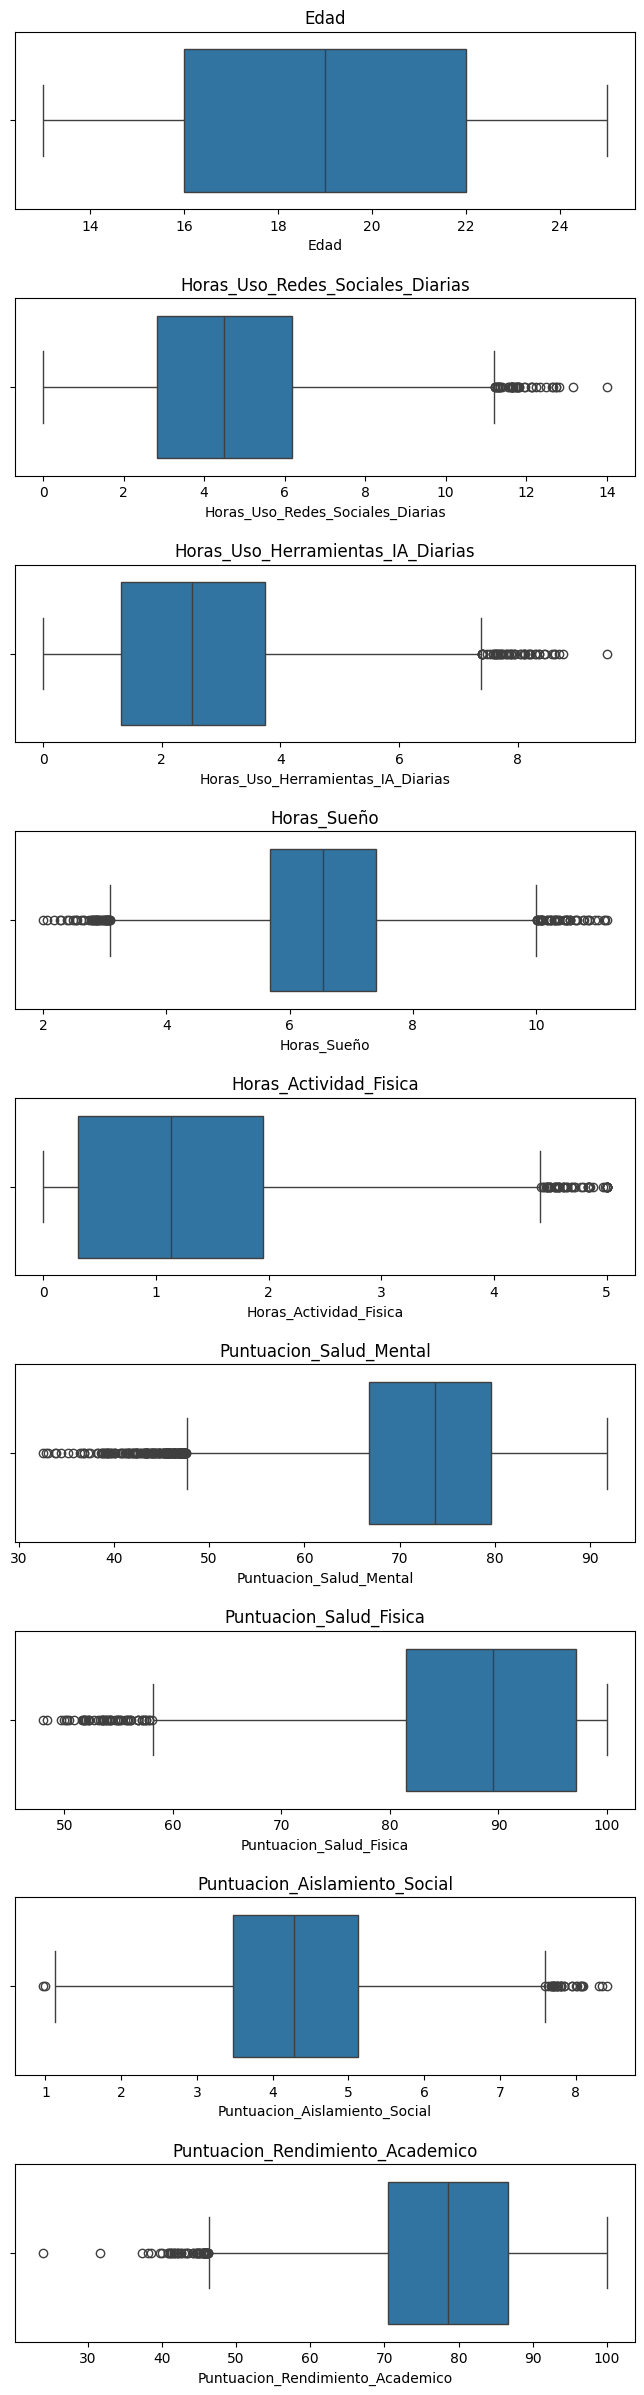

In [ ]:
cols_num = ['Edad', 'Horas_Uso_Redes_Sociales_Diarias', 'Horas_Uso_Herramientas_IA_Diarias', 'Horas_Sueño', 'Horas_Actividad_Fisica',
            'Puntuacion_Salud_Mental', 'Puntuacion_Salud_Fisica','Puntuacion_Aislamiento_Social','Puntuacion_Rendimiento_Academico'] # aqui vericaremos que columnas numericas poseen valores extremos

fig, ax = plt.subplots(nrows=9, ncols=1, figsize=(8,30))
fig.subplots_adjust(hspace=0.5)



for i, col in enumerate(cols_num):
    sns.boxplot(x=col, data=data, ax=ax[i]) # generamos un boxplot para cada columna numerica de col_num con seaborn cada categoria tendra su propio histograma indicado en el argumento ax=ax[i]
    ax[i].set_title(col)

#Graficación de la variables cualitativas para verificar si posee algun valor anormal

(array([4597.,    0.,    0.,    0.,    0., 5693.,    0.,    0.,    0.,
        4710.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

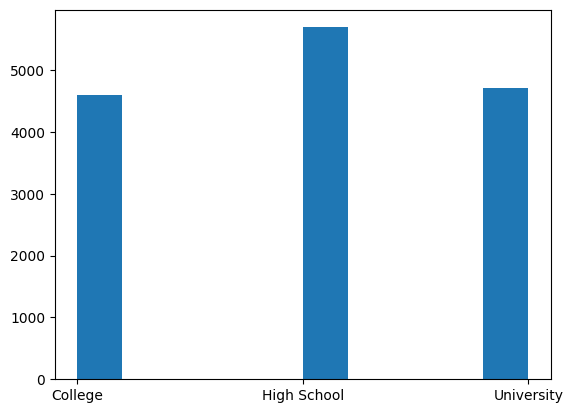

In [ ]:
plt.hist(data['Nivel_Educacion'])

(array([9000.,    0.,    0., 4200.,    0.,    0., 1350.,    0.,    0.,
         450.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

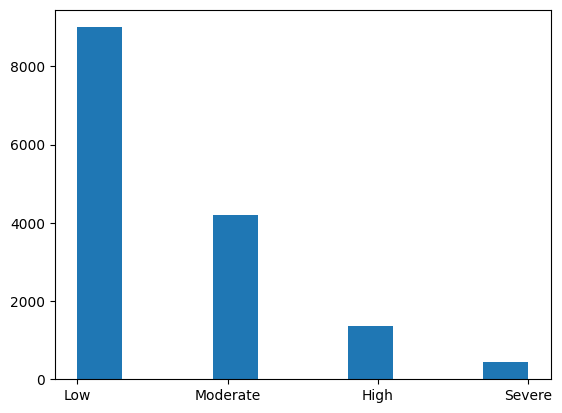

In [ ]:
plt.hist(data['Nivel_Agotamiento'])

Las variables categóricas no presentan valores outliers por lo que no ameritan algún tratamiento. Por otro lado, en las variables cuantitativas se presentan valores fuera de lo normal, pero dentro de lo posible en las rutinas de los estudiantes. Por ejemplo, uso de redes sociales, donde tenemos casos que tienen 11 horas de uso, saliéndose del uso promedio, pero que llega a ser una posibilidad real en el mundo digital. Lo mismo pasa con el otro rango de 2 a 6 horas; también tenemos horas de sueño donde tenemos outliers tanto encima como abajo con personas con 10 horas de sueño, algo no normal, pero que entra de lo posible en las rutinas de estudiantes. Por lo mencionado anteriormente no ameritan tratamiento.

#Matriz de correlacion entre variables

**Riesgo_Fracaso_Academico(variable objectivo)

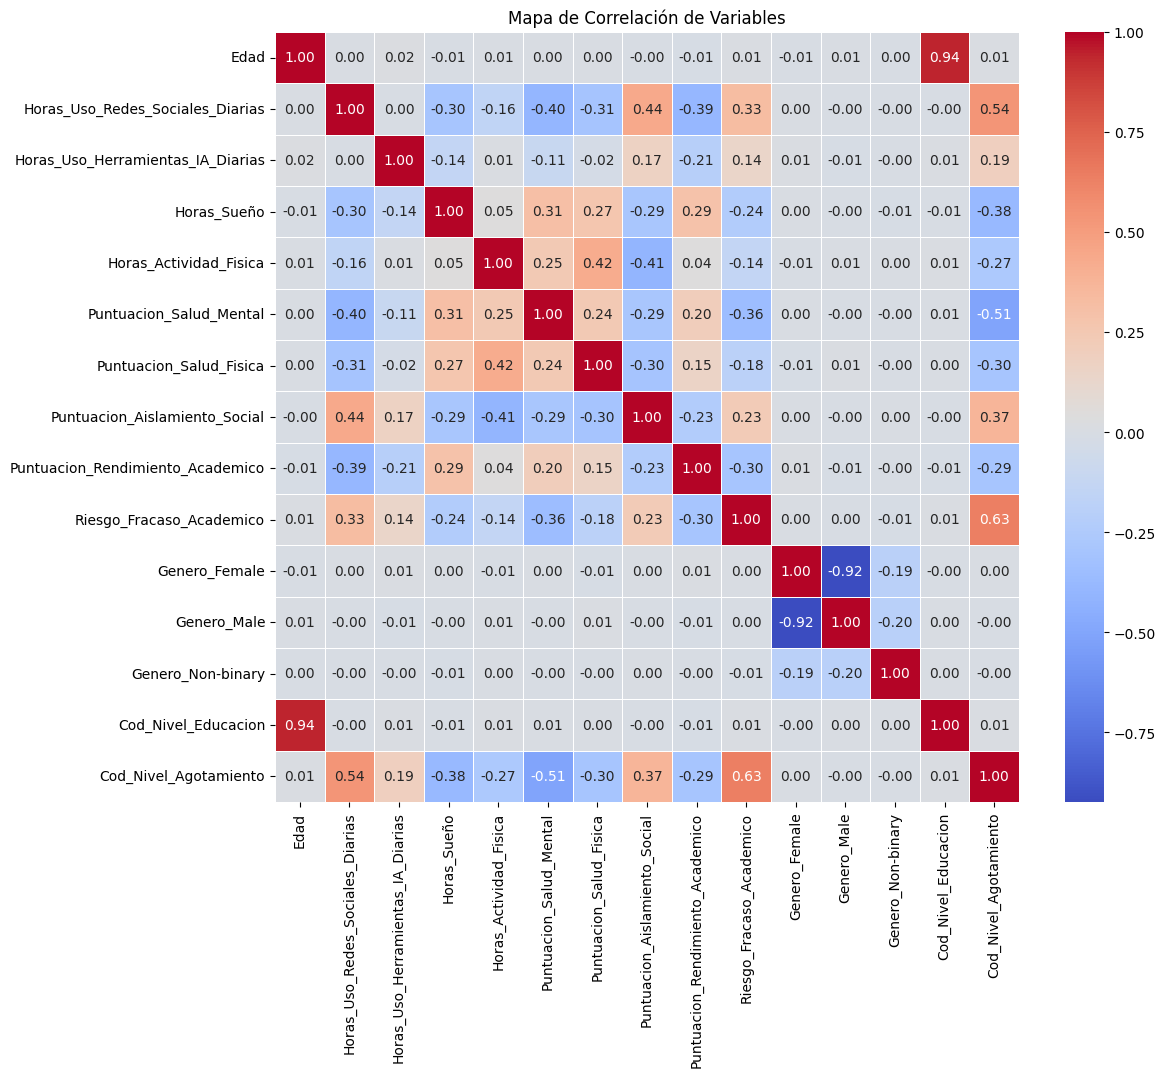

In [ ]:
#Se excluyen las variables no numericas.

excluded_columns = ['ID_Estudiante', 'Genero_copiado','Nivel_Educacion','Nivel_Agotamiento']
correlation_matrix = data.drop(columns=excluded_columns, errors='ignore').corr()


plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Mapa de Correlación de Variables')
plt.show()

Como vemos en la matriz de correlación, vemos cómo existen múltiples variables relacionadas con nuestra variable objetivo (Riesgo_Fracaso_Académico). Entre las más importantes está Uso_Redes_Sociales_Diarias, donde presenta una relación lineal de 0.33 que nos indica que el uso de redes sociales incide en una alta posibilidad de fracaso académico. Hablando de otras, tenemos también nivel de agotamiento con 0,64 la de mayor incidencia en nuestra variable objetivo. Por último, mencionando algunas más, tenemos horas_sueño con relación inversa, indicando que a mayor horas de sueño, menor posibilidad de fracaso académico. Por lo anterior, se puede concluir que en nuestro dataset existen las suficientes relaciones entre la variable objetivo y las variables predictoras para su uso en modelos de machine learning.

#Balanceo de clases

In [ ]:

print('Cantidad fila y columnas:', data.shape)
display(data.head())
print('\nDistribución de la clase objetivo (Riesgo_Fracaso_Academico):')
print(data['Riesgo_Fracaso_Academico'].value_counts())
print('\nProporciones:')
print(data['Riesgo_Fracaso_Academico'].value_counts(normalize=True))

Cantidad fila y columnas: (15000, 18)


,ID_Estudiante,Edad,Nivel_Educacion,Horas_Uso_Redes_Sociales_Diarias,Horas_Uso_Herramientas_IA_Diarias,Horas_Sueño,Horas_Actividad_Fisica,Puntuacion_Salud_Mental,Puntuacion_Salud_Fisica,Puntuacion_Aislamiento_Social,Nivel_Agotamiento,Puntuacion_Rendimiento_Academico,Riesgo_Fracaso_Academico,Genero_Female,Genero_Male,Genero_Non-binary,Cod_Nivel_Educacion,Cod_Nivel_Agotamiento
0,STU_00001,19,College,5.32,1.21,7.30,1.41,74.06,98.90,4.05,Low,88.80,0,0,1,0,1,0
1,STU_00002,16,High School,5.21,3.89,7.81,2.48,76.13,89.94,4.65,Moderate,50.60,0,0,0,1,0,1
2,STU_00003,25,University,3.61,2.65,6.34,0.06,65.01,76.75,5.28,Low,96.67,0,0,1,0,2,0
3,STU_00004,23,University,2.93,1.43,6.12,1.37,74.67,87.38,3.66,Low,85.65,0,0,1,0,2,0
4,STU_00005,20,College,6.52,1.64,5.23,1.14,67.74,88.04,3.25,Moderate,71.84,0,0,0,1,1,1



Distribución de la clase objetivo (Riesgo_Fracaso_Academico):
Riesgo_Fracaso_Academico
0    14100
1      900
Name: count, dtype: int64

Proporciones:
Riesgo_Fracaso_Academico
0    0.94
1    0.06
Name: proportion, dtype: float64


Al analizar las proporciones de nuestra variable objetivo, evidenciamos que se presenta un altísimo grado de desbalanceo, concentrándose mayormente en 0 indicando no fracaso, por lo cual amerita un balanceo para equilibrar este problema.

#Separacion De X y Y

In [ ]:
# Separar X,y Y escalar
X = data.drop(columns=['Riesgo_Fracaso_Academico', 'ID_Estudiante', 'Nivel_Educacion', 'Nivel_Agotamiento', 'Cod_Nivel_Agotamiento'])
y = data['Riesgo_Fracaso_Academico']

scaler = StandardScaler() #  se estandarizo(evitar confuciones)
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)




display(X_scaled.head())

,Edad,Horas_Uso_Redes_Sociales_Diarias,Horas_Uso_Herramientas_IA_Diarias,Horas_Sueño,Horas_Actividad_Fisica,Puntuacion_Salud_Mental,Puntuacion_Salud_Fisica,Puntuacion_Aislamiento_Social,Puntuacion_Rendimiento_Academico,Genero_Female,Genero_Male,Genero_Non-binary,Cod_Nivel_Educacion
0,-0.010795,0.326257,-0.819211,0.595241,0.157628,0.167314,1.123535,-0.225421,0.908255,-0.953481,1.031840,-0.202702,0.078936
1,-0.807157,0.280394,0.777993,0.996902,1.188145,0.391214,0.198291,0.290756,-2.400747,-0.953481,-0.969143,4.933339,-1.125587
2,1.581929,-0.386714,0.038988,-0.160826,-1.142555,-0.811575,-1.163759,0.832741,1.589979,-0.953481,1.031840,-0.202702,1.283460
3,1.051021,-0.670235,-0.688097,-0.334092,0.119105,0.233294,-0.066064,-0.560935,0.635393,-0.953481,1.031840,-0.202702,1.283460
4,0.254659,0.826588,-0.562943,-1.035029,-0.102408,-0.516286,0.002090,-0.913656,-0.560872,-0.953481,-0.969143,4.933339,0.078936


Se estandariza las variables en x para evitar confusiones con la escalas para el modelo.

In [ ]:
#funcion para evaluar el modelo
def evaluate_classifier(clf, X_train, X_test, y_train, y_test, use_predict_proba=False):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    return {
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'accuracy': accuracy_score(y_test, y_pred)
    }

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42,
                                                    stratify=y)#stratify se iguala la data en el 80 training/20 test
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('\nDistribución en training:')
print(y_train.value_counts(normalize=True))
print('\nDistribución en test:')
print(y_test.value_counts(normalize=True))

Train shape: (12000, 13) Test shape: (3000, 13)

Distribución en training:
Riesgo_Fracaso_Academico
0    0.94
1    0.06
Name: proportion, dtype: float64

Distribución en test:
Riesgo_Fracaso_Academico
0    0.94
1    0.06
Name: proportion, dtype: float64


Evideciamos que nuestro datos para training y para test mantinenen la misma proporcion del dataset original permitiendonos un entrenamieto optimo para los modelos.

In [ ]:
# Aplicando: SMOTE (Synthetic Minority Oversampling) #se iguala la minoritaria a la mayoritaria (subiendo) con datos sinteticos

sampler = SMOTE(random_state=42)
X_res, y_res = sampler.fit_resample(X_train, y_train)
print('Después de SMOTE (Synthetic Minority Oversampling):', pd.Series(y_res).value_counts())
# Guardar como variables con nombre específico
X_res_SMOTE = X_res
y_res_SMOTE = y_res
X_res.shape

Después de SMOTE (Synthetic Minority Oversampling): Riesgo_Fracaso_Academico
0    11280
1    11280
Name: count, dtype: int64


(22560, 13)

Luego de aplicar varias técnicas de balanceo a nuestro dataset, evidenciamos que, en general el balanceo en las técnicas oversampling y SMOTE se evidencia como las mejores, ya que equilibran ambas opciones de la mejor manera. Finalmente, se optó por tomar SMOTE como la técnica de balanceo ideal para nuestro caso por su técnica de balanceo con datos sintéticos.

In [ ]:
# Seleccionar datasets balanceados creados arriba: buscamos variables en el notebook globals()
balanced_keys = [k for k in globals().keys() if k.startswith('X_res_')]
balanced_keys

['X_res_SMOTE']

In [ ]:

  # Definir modelos base
models = {
    'LogisticRegression': LogisticRegression(solver='liblinear', random_state=42),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42)
}
# KMeans will be handled separately per dataset
results = {}

for key in balanced_keys:
    X_res = globals()[key]
    y_res = globals()[key.replace('X_res_','y_res_')]
    print('\n==== Dataset balanceado:', key, 'shape:', X_res.shape, 'Class distribution:', pd.Series(y_res).value_counts().to_dict())

    #se evalua cada modelo donde se entrena con x_res que proviene del remuestreo y evaluaremos con x test para validar la calidad con datos cercanos a la realidad
    for name, clf in models.items():
        res = evaluate_classifier(clf, X_res, X_test, y_res, y_test)
        results[f'{key}_{name}'] = res

# Imprecion de los resultados para cada modelo
import pandas as pd
rows = []
for k,v in results.items():
    rows.append({'dataset_model': k, **v})
res_df = pd.DataFrame(rows).set_index('dataset_model')
display(res_df)


==== Dataset balanceado: X_res_SMOTE shape: (22560, 13) Class distribution: {0: 11280, 1: 11280}


,precision,recall,f1,accuracy
dataset_model,,,,
X_res_SMOTE_LogisticRegression,0.338086,0.922222,0.494784,0.887000
X_res_SMOTE_DecisionTree,0.353293,0.655556,0.459144,0.907333
X_res_SMOTE_RandomForest,0.490421,0.711111,0.580499,0.938333


Luego de ejecutar los modelos con la técnica de balanceo SMOTE, se logra evidenciar un alto nivel en acurrancy en los tres modelos, lo que nos permite concluir que la selección de la técnica fue la decisión correcta para evaluar con los modelos.

In [ ]:
# Prueba de los modelos indico al sistema que los datos estan desbaleanceados
models_balanced = {
    'LogisticRegression_balanced': LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42),
    'DecisionTree_balanced': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'RandomForest_balanced': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
}

results_balanced = {}
for name, clf in models_balanced.items():
    res = evaluate_classifier(clf, X_train, X_test, y_train, y_test)
    results_balanced[name] = res

res_bal_df = pd.DataFrame([{'model':k, **v} for k,v in results_balanced.items()]).set_index('model')
display(res_bal_df)

,precision,recall,f1,accuracy
model,,,,
LogisticRegression_balanced,0.323643,0.927778,0.479885,0.879333
DecisionTree_balanced,0.426966,0.422222,0.424581,0.931333
RandomForest_balanced,0.697674,0.333333,0.451128,0.951333


Luego de evaluar el metodo anterior de indicarle al sistema que los datos estan desbaleanceados y el propio sistema lo balanceara se evidencia un resultado similar en la mayoria de metricas indicando que tanto usando metodos de balanceo como indicandole al sistema en este caso el resultado se matiene estable.

#APLICACIÓN DE MODELOS

#Modelo Multinomial - Regresión Logística

In [ ]:
model = LogisticRegression(multi_class='multinomial', solver='lbfgs',
                           max_iter=10000, random_state=42) # Se eliminó class_weight='balanced' ya que los datos ya están balanceados por SMOTE
model.fit(X_res_SMOTE, y_res_SMOTE) # entrenamiento del modelo con datos balanceados por SMOTE
print('Modelo de Regresión Logística Multinomial entrenado con éxito usando datos SMOTE.')

Modelo de Regresión Logística Multinomial entrenado con éxito usando datos SMOTE.


##Predicciones

In [ ]:
y_pred_rl2 = model.predict(X_test) # Clase predicha
y_proba = model.predict_proba(X_test) # Probabilidad

In [ ]:
print(y_proba)

[[9.15154623e-01 8.48453774e-02]
 [6.81226774e-01 3.18773226e-01]
 [9.74891967e-01 2.51080327e-02]
 ...
 [9.88174661e-01 1.18253386e-02]
 [9.86903852e-01 1.30961477e-02]
 [9.99908139e-01 9.18605810e-05]]


##Metricas Generales

In [ ]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rl2), # les paso la respuesta correcta y la del modelo a todas
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred_rl2), # como nos fue teniendo en cuenta el desbalanceo
    'Precision (macro)': precision_score(y_test, y_pred_rl2, average='macro'),
    'Recall (macro)': recall_score(y_test, y_pred_rl2, average='macro'),
    'F1-score (macro)': f1_score(y_test, y_pred_rl2, average='macro'),
    'Log Loss': log_loss(y_test, y_proba), # que tan inseguro estuvo el modelo al dar la predicion(mas bajo mejor)
    'Roc Auc': roc_auc_score(y_test, y_proba[:, 1]) # Se usa y_proba[:, 1] para obtener las probabilidades de la clase positiva (clase 1)
}
print(pd.Series(metrics))

Accuracy             0.887333
Balanced Accuracy    0.903664
Precision (macro)    0.666599
Recall (macro)       0.903664
F1-score (macro)     0.716054
Log Loss             0.266367
Roc Auc              0.960181
dtype: float64


##Matriz de Confusión


--- Matriz de Confusión ---



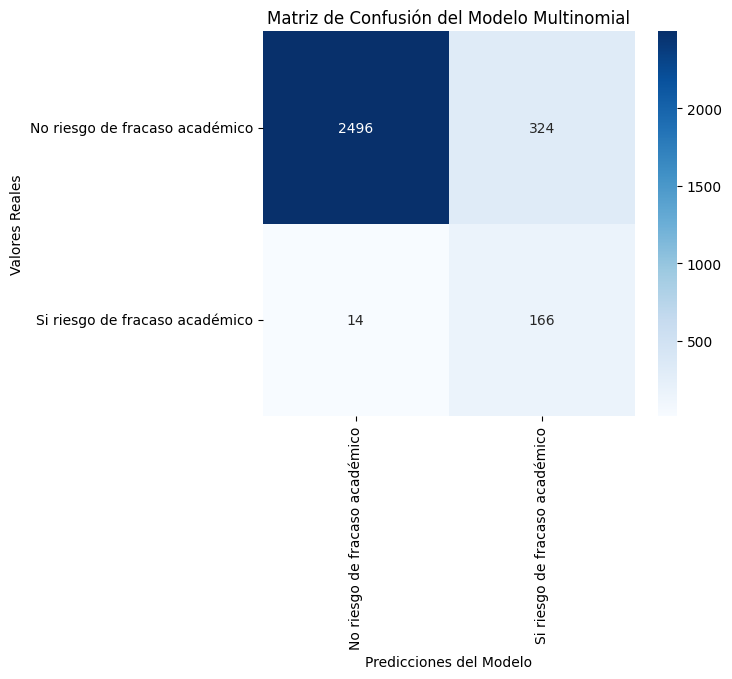


--- Reporte de Clasificación ---

                                precision    recall  f1-score   support

No riesgo de fracaso académico       0.99      0.89      0.94      2820
Si riesgo de fracaso académico       0.34      0.92      0.50       180

                      accuracy                           0.89      3000
                     macro avg       0.67      0.90      0.72      3000
                  weighted avg       0.96      0.89      0.91      3000


--- Exactitud del Modelo ---

0.8873333333333333


In [ ]:
target_class_names = ['No riesgo de fracaso académico', 'Si riesgo de fracaso académico']

#  Evaluar el rendimiento del modelo
print('\n--- Matriz de Confusión ---\n')
cm = confusion_matrix(y_test, y_pred_rl2)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_class_names, yticklabels=target_class_names)
plt.ylabel('Valores Reales')
plt.xlabel('Predicciones del Modelo')
plt.title('Matriz de Confusión del Modelo Multinomial')
plt.show()

print('\n--- Reporte de Clasificación ---\n')
print(classification_report(y_test, y_pred_rl2, target_names=target_class_names))
print('\n--- Exactitud del Modelo ---\n')
print(accuracy_score(y_test, y_pred_rl2))

##Interpretaciones

Luego de graficar la matriz de confusión para nuestro modelo multinomial, se logra evidenciar que el modelo logró evidenciar lo siguiente:

* De 2,820 registros en riesgo de no fracaso auténticos (0), clasificó correctamente 2,496.

* De 180 registros con riesgo de fracaso académico auténticos (1), clasificó correctamente 166.

* Predijo 490 casos con riesgo de fracaso académico, fallando en 324 casos, mostrando que el modelo tendió a fallar más al clasificar esta clase.

* Para la clase 1 (Sí riesgo de fracaso académico): la métrica de recall fue de 92%, indicando que el modelo fue capaz de identificar una gran mayoría de los casos reales de riesgo de fracaso académico en el dataset. Por otro lado, su precisión para la clase 1 es del 0,34, indicando que cuando el modelo dijo que 490 casos tenían riesgo, solo acerto en el 34 % de ellos.

* Para la Clase 0 (No riesgo de fracaso académico): la métrica de precisión nos indica un 0.99, lo que significa que en la mayoría de las oportunidades que el modelo dijo que no tenía riesgo, acertó. Y su recall fue de un 0.89, lo que nos dice que el modelo identificó el 89% de todos los posibles no riesgos de fracaso. Métricas esperables al ser la clase mayoritaria.

Por otra parte, el Log Loss fue de 0,266 (mientras más bajo, mejor). Como el modelo se entrenó con datos balanceados por SMOTE, sus probabilidades tienden a sobreestimar el riesgo. También tenemos el ROC AUC de 0,96 - 96%, que indica que el modelo diferencia bien a los estudiantes con riesgo de los que no lo tienen.

Finalmente, se puede concluir que el modelo tiende a predecir de mejor manera la clase 0, la mayoritaria, por sus destacadas métricas de precisión con un 99%, recall con 89% y f1 score con 94%, dando a entender esta última métrica un alto equilibrio entre precisión y recall, a diferencia de la clase 1, donde su f1 score fue 50%, bastante bajo en comparación. El modelo alcanza un Accuracy de 0.8873 - 88,73%


#Maquina de Soporte Vectorial - SVM

In [ ]:
#Crear y entrenar el modelo SVM
# Usamos el kernel 'rbf' debido a a las multiples variables que inciden en la variable objetivo
# Se eliminó class_weight='balanced' ya que los datos ya están balanceados por SMOTE
svc_model = SVC(kernel='rbf', random_state=42, probability=True) # probability=True para poder calcular log_loss

# Entrenar el modelo con los datos balanceados por SMOTE
svc_model.fit(X_res_SMOTE, y_res_SMOTE)

print('Modelo SVC entrenado con éxito usando datos SMOTE. Kernel utilizado: rbf')

Modelo SVC entrenado con éxito usando datos SMOTE. Kernel utilizado: rbf


##Predicciones

In [ ]:
#  Realizar predicciones
y_pred_svm = svc_model.predict(X_test)
y_proba_svm = svc_model.predict_proba(X_test) # Probabilidad

print(y_proba_svm)

[[9.42418269e-01 5.75817305e-02]
 [5.30514034e-01 4.69485966e-01]
 [9.98211162e-01 1.78883784e-03]
 ...
 [9.98873431e-01 1.12656916e-03]
 [9.78761309e-01 2.12386912e-02]
 [9.99974753e-01 2.52471672e-05]]


##Metricas de Evaluación

In [ ]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_svm), # les paso la respuesta correcta y la del modelo a todas
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred_svm), # como nos fue teniendo en cuenta el desbalanceo
    'Precision (macro)': precision_score(y_test, y_pred_svm, average='macro'),
    'Recall (macro)': recall_score(y_test, y_pred_svm, average='macro'),
    'F1-score (macro)': f1_score(y_test, y_pred_svm, average='macro'),
    'Log Loss': log_loss(y_test, y_proba_svm), # que tan inseguro estuvo el modelo al dar la predicion(mas bajo mejor)
    'Roc Auc': roc_auc_score(y_test, y_proba_svm[:, 1]) # Se usa y_proba_svm[:, 1] para obtener las probabilidades de la clase positiva (clase 1)

}
print(pd.Series(metrics))

Accuracy             0.894000
Balanced Accuracy    0.857801
Precision (macro)    0.663714
Recall (macro)       0.857801
F1-score (macro)     0.710686
Log Loss             0.231654
Roc Auc              0.943300
dtype: float64


##Matriz de confusión


--- Matriz de Confusión ---



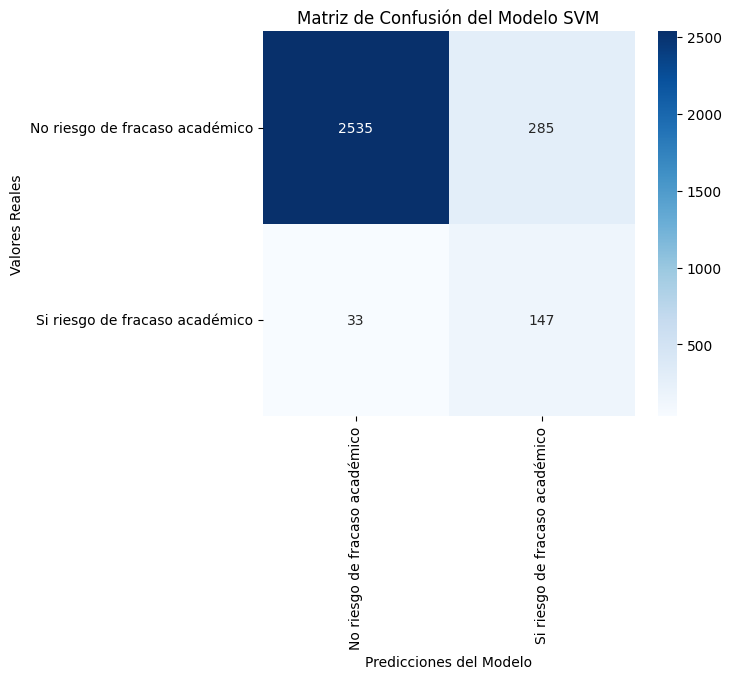


--- Reporte de Clasificación ---

                                precision    recall  f1-score   support

No riesgo de fracaso académico       0.99      0.90      0.94      2820
Si riesgo de fracaso académico       0.34      0.82      0.48       180

                      accuracy                           0.89      3000
                     macro avg       0.66      0.86      0.71      3000
                  weighted avg       0.95      0.89      0.91      3000


--- Exactitud del Modelo ---

0.894


In [ ]:
target_class_names = ['No riesgo de fracaso académico', 'Si riesgo de fracaso académico']

#  Evaluar el rendimiento del modelo
print('\n--- Matriz de Confusión ---\n')
cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_class_names, yticklabels=target_class_names)
plt.ylabel('Valores Reales')
plt.xlabel('Predicciones del Modelo')
plt.title('Matriz de Confusión del Modelo SVM')
plt.show()

print('\n--- Reporte de Clasificación ---\n')
print(classification_report(y_test, y_pred_svm, target_names=target_class_names))
print('\n--- Exactitud del Modelo ---\n')
print(accuracy_score(y_test, y_pred_svm))

##Interpretaciones

Luego de graficar la matriz de confusión para nuestro modelo SVM, se puede evidenciar que el modelo presenta un desempeño diferente entre las dos clases de la variable objetivo:

* De 2.820 registros de no riesgo de fracaso académico auténticos (0) clasificó correctamente 2535(VP).

* De 180 registros con riesgo de fracaso académico auténticos (1) clasificó correctamente 147(VP).

* Predijo un total de 432 casos con riesgo de fracaso académico, de los cuales 285 correspondieron a falsos positivos (FP), mostrando que el modelo tendió a generar una cantidad considerable de falsos positivos al clasificar esta clase.

* Para la clase 0 (No riesgo de fracaso académico), el modelo obtuvo una precisión de 99%, lo que indica que cuando el modelo predijo que un estudiante no presentaba riesgo, acertó en la mayoría de los casos. Por otro lado, obtuvo un recall de 90%, indicando que logró identificar correctamente el 90% de los estudiantes que realmente pertenecían a esta clase.

* Para la clase 1 (Sí riesgo de fracaso académico), el modelo obtuvo una precisión de 34%, lo que indica que de los estudiantes que el modelo clasificó como estar en riesgo, una proporción relativamente baja correspondía realmente a esta clase. Por otra parte, el recall fue de 82%, indicando que el modelo logró identificar correctamente aproximadamente cuatro quintas partes de los estudiantes que realmente presentaban riesgo de fracaso académico.

La diferencia entre ambas clases es importante, ya que la clase 0 cuenta con 2.820 registros, mientras que la clase 1 solamente cuenta con 180 registros. Por esta razón, las métricas de la clase mayoritaria son considerablemente superiores a las de la clase minoritaria. El modelo presenta mayor dificultad para realizar predicciones precisas cuando identifica estudiantes como pertenecientes a la clase de riesgo, aunque logra detectar una mayor proporción de los casos reales de esta clase.

El modelo obtuvo un Accuracy de 89,40%, lo que significa que clasificó correctamente aproximadamente el 89% de los 3.000 registros del conjunto de prueba. Sin embargo, debido al desbalance entre las clases, esta métrica debe analizarse junto con la precision, recall y F1-score para comprender correctamente el comportamiento del modelo.

Finalmente, se puede concluir que el SVM presenta un buen desempeño para identificar la clase 0 (No riesgo de fracaso académico), con una precisión de 99%, recall de 90% y F1-score de 94%. Sin embargo, presenta mayores dificultades para clasificar la clase 1 (Sí riesgo de fracaso académico), especialmente en precisión, que fue de 34%. Por otro lado, el recall de 82% indica que logra detectar una proporción importante de los estudiantes que realmente presentan riesgo. Por lo tanto, aunque el modelo alcanza un Accuracy de  0.894 - 89,40%, su desempeño no es igual para ambas clases y tiene mayor dificultad para realizar predicciones precisas sobre los estudiantes que presentan riesgo de fracaso académico.

#Árboles de Desición - DecisionTree

In [ ]:
model_DecisionTree = DecisionTreeClassifier(random_state=42)
model_DecisionTree.fit(X_res_SMOTE, y_res_SMOTE)


DecisionTreeClassifier(random_state=42)

##Predicciones

In [ ]:
y_pred_tree = model_DecisionTree.predict(X_test)
y_proba = model_DecisionTree.predict_proba(X_test)
print(y_pred_tree)

[0 0 0 ... 0 0 0]


##Metricas de Evaluación

In [ ]:
accuracy = accuracy_score(y_test, y_pred_tree)
precision = precision_score(y_test, y_pred_tree, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_tree, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_tree, average='macro', zero_division=0)

try:
    roc_auc = roc_auc_score(y_test, y_proba[:, 1], multi_class='ovr', average='macro')
except:
    roc_auc = None

print("Métricas del modelo inicial:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("ROC AUC Macro:", roc_auc)

Métricas del modelo inicial:
Accuracy: 0.9073333333333333
Precision: 0.6650187996100821
Recall: 0.7894799054373522
F1: 0.7042347624161112
ROC AUC Macro: 0.7894799054373521


##Importancia de Variables


Importancia de características:
Puntuacion_Salud_Mental              0.428381
Puntuacion_Rendimiento_Academico     0.225411
Horas_Uso_Redes_Sociales_Diarias     0.102610
Horas_Sueño                          0.044798
Horas_Uso_Herramientas_IA_Diarias    0.042235
Puntuacion_Salud_Fisica              0.036136
Horas_Actividad_Fisica               0.035834
Edad                                 0.035406
Puntuacion_Aislamiento_Social        0.030438
Genero_Male                          0.008825
Cod_Nivel_Educacion                  0.003967
Genero_Non-binary                    0.003230
Genero_Female                        0.002729
dtype: float64


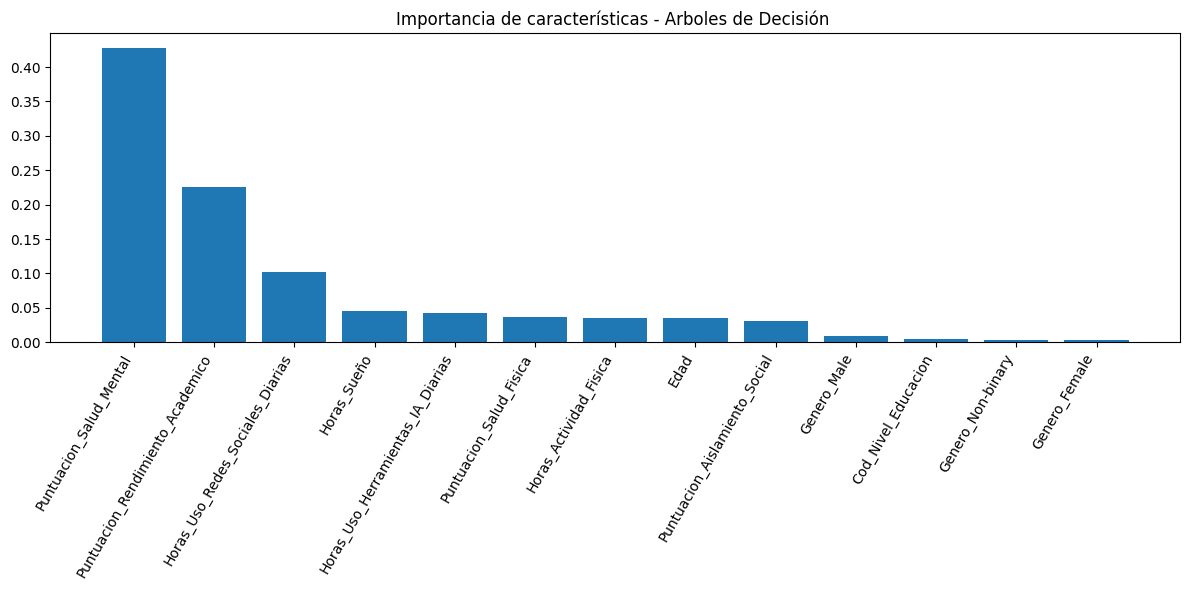

In [ ]:
importancias_decision = pd.Series(model_DecisionTree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nImportancia de características:")
print(importancias_decision)


# Gráfico
plt.figure(figsize=(12, 6))
plt.bar(importancias_decision.index, importancias_decision.values)
plt.title('Importancia de características - Arboles de Decisión ')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()

In [ ]:
#Ajustar modelo tree
modeloTree_ajustado = DecisionTreeClassifier(
    criterion="entropy",    # usar entropía en lugar de gini
    max_depth=5,           # limitar profundidad para evitar sobreajuste
    min_samples_split=4,   # más muestras para dividir un nodo
    min_samples_leaf=2,    # mínimo de observaciones en cada hoja
    ccp_alpha=0.01,        # poda para reducir complejidad
    random_state=42,
    max_features='sqrt'
)
modeloTree_ajustado.fit(X_res_SMOTE, y_res_SMOTE)

y_pred_ajustado = modeloTree_ajustado.predict(X_test)
y_proba_ajustado = modeloTree_ajustado.predict_proba(X_test)

# Métricas ajustadas
accuracy_ajustado = accuracy_score(y_test, y_pred_ajustado)
precision_ajustado = precision_score(y_test, y_pred_ajustado, average='macro', zero_division=0)
recall_ajustado = recall_score(y_test, y_pred_ajustado, average='macro', zero_division=0)
f1_ajustado = f1_score(y_test, y_pred_ajustado, average='macro', zero_division=0)

try:
    roc_auc_ajustado = roc_auc_score(y_test, y_proba_ajustado[:, 1], multi_class='ovr', average='macro')
except:
    roc_auc_ajustado = None

print("Métricas del modelo ajustado con hiperparámetros:")
print("Accuracy:", accuracy_ajustado)
print("Precision:", precision_ajustado)
print("Recall:", recall_ajustado)
print("F1:", f1_ajustado)
print("ROC AUC Macro:", roc_auc_ajustado)

Métricas del modelo ajustado con hiperparámetros:
Accuracy: 0.794
Precision: 0.6004795857737034
Recall: 0.8358156028368795
F1: 0.6088528375258233
ROC AUC Macro: 0.9037214342001576


##Matriz de confusión


--- Matriz de Confusión ---



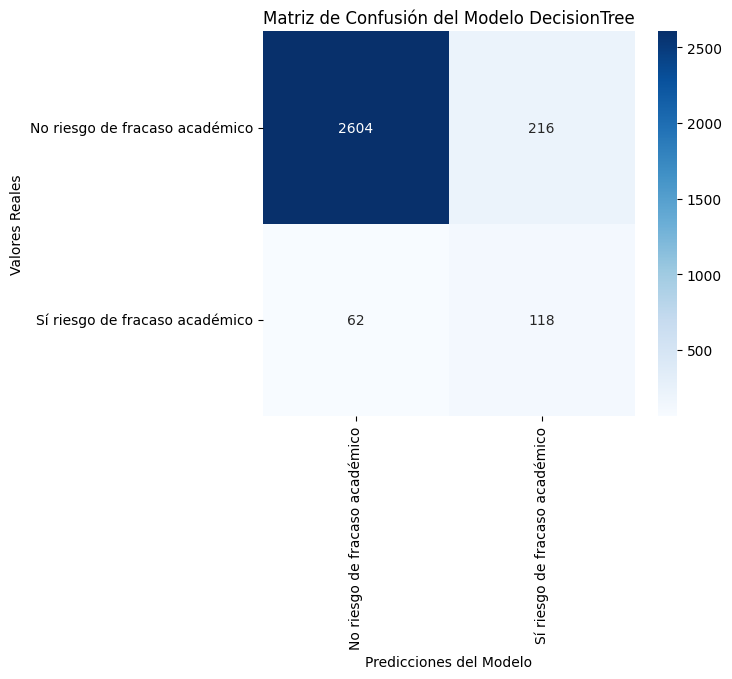


--- Reporte de Clasificación ---

                                precision    recall  f1-score   support

No riesgo de fracaso académico       0.98      0.92      0.95      2820
Sí riesgo de fracaso académico       0.35      0.66      0.46       180

                      accuracy                           0.91      3000
                     macro avg       0.67      0.79      0.70      3000
                  weighted avg       0.94      0.91      0.92      3000


--- Exactitud del Modelo ---

0.9073333333333333


In [ ]:
target_class_names = ['No riesgo de fracaso académico', 'Sí riesgo de fracaso académico']

#  Evaluar el rendimiento del modelo Decision Tree
print('\n--- Matriz de Confusión ---\n')
cm = confusion_matrix(y_test, y_pred_tree)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_class_names, yticklabels=target_class_names)
plt.ylabel('Valores Reales')
plt.xlabel('Predicciones del Modelo')
plt.title('Matriz de Confusión del Modelo DecisionTree')
plt.show()

print('\n--- Reporte de Clasificación ---\n')
print(classification_report(y_test, y_pred_tree, target_names=target_class_names))
print('\n--- Exactitud del Modelo ---\n')
print(accuracy_score(y_test, y_pred_tree))

##Interpretaciones

Luego de graficar la matriz de confusión para nuestro modelo Decision Tree, se puede evidenciar que el modelo presenta un desempeño diferente entre las dos clases de la variable objetivo.

De 2,820 registro en riesgo de no fracaso autenticos (0) clasifico correctamente 2604.

De 180 registros con riesgo de fracaso academico autenticos (1) clasifico correctamente 118.

Predijo 334 casos con riesgo de fracaso academico fallando en 216 casos, mostrando que el modelo tendio fallar mas al clasificar esta clase.


Para la clase 0 (No riesgo de fracaso académico), el modelo obtuvo una precision de 98%, lo que indica que cuando el modelo predijo que un estudiante no presentaba riesgo, acertó en la mayoría de los casos. Por otro lado, obtuvo un recall de 92%, indicando que logró identificar correctamente el 92% de los estudiantes que realmente pertenecían a esta clase.

*Para la clase 1 (Sí riesgo de fracaso académico), el modelo obtuvo una precision de 35%, lo que indica que de los estudiantes que el modelo clasificó como estar en riesgo, una proporción relativamente baja correspondía realmente a esta clase. Por otra parte, el recall fue de 66%, indicando que el modelo logró identificar correctamente aproximadamente dos terceras partes de los estudiantes que realmente presentaban riesgo de fracaso académico.

La diferencia entre ambas clases es importante, ya que la clase 0 cuenta con 2.820 registros, mientras que la clase 1 solamente cuenta con 180 registros. Por esta razón, las métricas de la clase mayoritaria son considerablemente superiores a las de la clase minoritaria. El modelo presenta mayor dificultad para realizar predicciones precisas cuando identifica estudiantes como pertenecientes a la clase de riesgo.

El modelo obtuvo un Accuracy de 90,73%, lo que significa que clasificó correctamente aproximadamente el 91% de los 3.000 registros del conjunto de prueba. Sin embargo, debido al desbalance existente entre las clases, esta métrica debe analizarse junto con precision, recall y F1-score para comprender correctamente el comportamiento del modelo.


Finalmente, se puede concluir que el Decision Tree presenta un buen desempeño para identificar la clase 0 (No riesgo de fracaso académico), con una precision de 98%, recall de 92% y F1-score de 95%. Sin embargo, presenta mayores dificultades para clasificar la clase 1 (Sí riesgo de fracaso académico), especialmente en la precision de 35% y F1-score de 46%. Su recall de 66% indica que logra detectar una proporción moderada de los estudiantes en riesgo. Por lo tanto, aunque el modelo alcanza un Accuracy de 90,73%, su desempeño no es igual para ambas clases y tiene mayor dificultad para realizar predicciones precisas sobre los estudiantes que presentan riesgo de fracaso académico.

#Árboles de Aleatorios - Random Forest

In [ ]:
# Modelo base RandomForestClassifier
rf_clf = RandomForestClassifier(random_state=42) # hiperaparametros por defecto
rf_clf.fit(X_res_SMOTE, y_res_SMOTE) # entrenamiento



RandomForestClassifier(random_state=42)

##Predicciones

In [ ]:
# Predicción y evaluación
y_pred_rf = rf_clf.predict(X_test) # evaluamos el modelo
y_proba_rf = rf_clf.predict_proba(X_test) # probabilidad
print(y_pred_rf)

[0 0 0 ... 0 0 0]


##Importancia de carateristicas


Importancia de características:
Puntuacion_Salud_Mental              0.252041
Horas_Uso_Redes_Sociales_Diarias     0.188281
Puntuacion_Rendimiento_Academico     0.185889
Horas_Sueño                          0.101076
Puntuacion_Aislamiento_Social        0.066667
Horas_Uso_Herramientas_IA_Diarias    0.050718
Horas_Actividad_Fisica               0.047396
Puntuacion_Salud_Fisica              0.047249
Edad                                 0.036133
Cod_Nivel_Educacion                  0.011748
Genero_Male                          0.005545
Genero_Female                        0.005158
Genero_Non-binary                    0.002099
dtype: float64


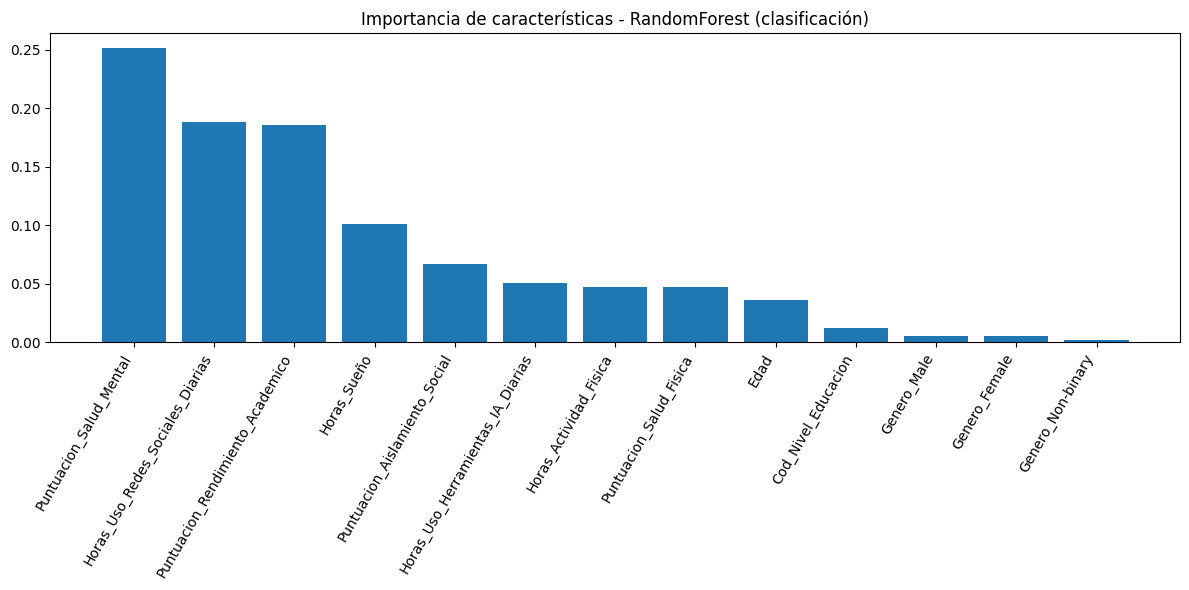

In [ ]:
importancias_random_claf = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nImportancia de características:")
print(importancias_random_claf)

# Gráfico
plt.figure(figsize=(12, 6))
plt.bar(importancias_random_claf.index, importancias_random_claf.values)
plt.title('Importancia de características - RandomForest (clasificación)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()

##Metricas de Evaluación

In [ ]:
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_rf, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_rf, average='macro', zero_division=0)

try:
  roc_auc = roc_auc_score(y_test, y_proba_rf[:, 1],multi_class='ovr', average='macro')
except:
    roc_auc = None

print("Métricas del modelo inicial:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("ROC AUC Macro:", roc_auc)

Métricas del modelo inicial:
Accuracy: 0.9383333333333334
Precision: 0.7357182124527367
Recall: 0.8319739952718677
F1: 0.7736097497102816
ROC AUC Macro: 0.9534003152088258


##Matriz de confusión

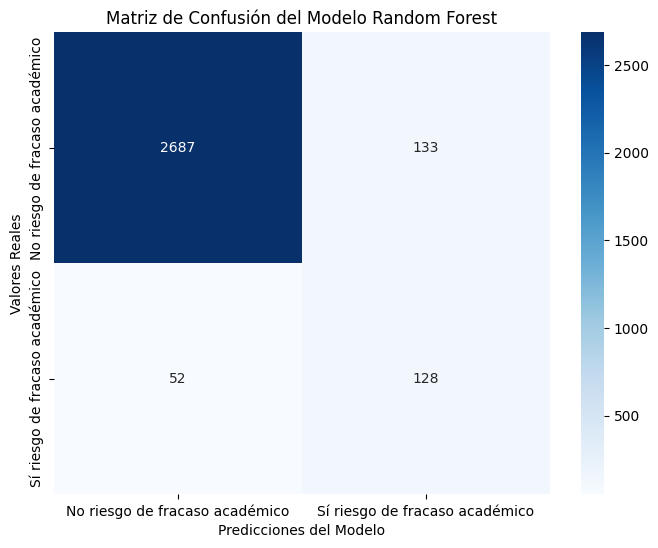


--- Reporte de Clasificación ---

                                precision    recall  f1-score   support

No riesgo de fracaso académico       0.98      0.95      0.97      2820
Sí riesgo de fracaso académico       0.49      0.71      0.58       180

                      accuracy                           0.94      3000
                     macro avg       0.74      0.83      0.77      3000
                  weighted avg       0.95      0.94      0.94      3000


--- Exactitud del Modelo ---

0.9383333333333334


In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',xticklabels=target_class_names, yticklabels=target_class_names)
plt.xlabel('Predicciones del Modelo')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión del Modelo Random Forest')
plt.show()


print('\n--- Reporte de Clasificación ---\n')
print(classification_report(y_test, y_pred_rf, target_names=target_class_names))
print('\n--- Exactitud del Modelo ---\n')
print(accuracy_score(y_test, y_pred_rf))

#Modelo Ajustado con hiperparametros

In [ ]:
param_dist = {
    'n_estimators': sp_randint(100, 250),  #número total de árboles de decisión que se van a construir dentro del modelo
    'max_depth': sp_randint(2, 15), # maxima profundida
    'min_samples_split': sp_randint(2, 10), # minimo de muestras para dividr un nodo
    'min_samples_leaf': sp_randint(5, 10), # minimo de muetras por hoja
    'max_features': ['auto', 'sqrt', 'log2'] # caracteriticas a usar tres opciones
}
#Busqueda aleatoria de los mejores hiperparametros
rs = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_dist,
                        n_iter=25, cv=5, random_state=42, n_jobs=-2)

rs.fit(X_res_SMOTE, y_res_SMOTE)

print('Mejor score CV:', rs.best_score_)
print('Mejores parámetros:', rs.best_params_) # parametros que dieron el mejor arbol

# Evaluamos el mejor modelo en el set de prueba
best_clf = rs.best_estimator_
y_pred_best = best_clf.predict(X_test)
print('Accuracy (mejor modelo):', accuracy_score(y_test, y_pred_best))
print("\nClassification report:\n", classification_report(y_test, y_pred_best))

Mejor score CV: 0.9524822695035461
Mejores parámetros: {'max_depth': 14, 'max_features': 'log2', 'min_samples_leaf': 6, 'min_samples_split': 3, 'n_estimators': 143}
Accuracy (mejor modelo): 0.9193333333333333

Classification report:
               precision    recall  f1-score   support

           0       0.98      0.93      0.96      2820
           1       0.41      0.78      0.54       180

    accuracy                           0.92      3000
   macro avg       0.70      0.85      0.75      3000
weighted avg       0.95      0.92      0.93      3000



#Interpretaciones Modelo Inicial
Luego de graficar la matriz de confusión para nuestro modelo de árboles aleatorios, se puede evidenciar que el modelo presenta un desempeño diferente entre las dos clases de la variable objetivo.

En las métricas del modelo inicial se obtuvieron los siguientes resultados:

Para la clase 0 (No riesgo de fracaso académico) De 2820 casos reales en esta clase, el modelo identificó correctamente 2687 casos, dando así un recall del 95%, mostrando que el modelo logró identificar la mayoría de los casos disponibles. Por otro lado, en precisión, el modelo clasificó 2739 como no riesgo, equivocándose solamente en 52 casos, dando así una precisión del 98%, mostrando que el modelo es muy bueno prediciendo y encontrando esta clase.

Para la clase 1 (Sí riesgo de fracaso académico) De 180 casos reales en esta clase, el modelo identificó 128 casos correctamente, dándonos un recall del 71%, permitiéndonos ver que el modelo es bastante bueno encontrando esta clase. Por otro lado, en su métrica de precisión, el modelo tuvo una métrica moderada de 49%, evidenciando que el modelo acertó en la mitad de sus predicciones, algo destacable al ser esta la clase minoritaria.

La diferencia entre las metricas de ambas clases es considerable esto se da ya que el modelo cuenta con una desproporcion en las clases que usa para hacer la predicciones aun asi en el caso del modelo de árboles aleatorios, se destaca una mejora considerable en las metricas de la clase 1 (Sí riesgo de fracaso academico) donde su metrica de presicion saca un 49% una mejora considerable a los demás modelos y en general saca este modelo una exactitud del 0.9383- 93,83% la mejor de todos los modelos evaluados en sus metricas iniciales.

Finalmente, se puede concluir que el modelo de árboles aleatorios presenta un excelente desempeño para identificar la clase 0 (No riesgo de fracaso académico), con una precisión de 98%, recall de 95% y F1-score de 97%. Sin embargo, el modelo también presenta destacables capacidades en identificar la clase 1 (Sí riesgo de fracaso académico), con una precisión del 49%, recall del 71% y un F1-score del 58%, siendo estas métricas una de las mejores hasta ahora por su equilibrio.



#Interpretacion Modelo Ajustado

Luego de aplicar los ajustes al modelo de árboles aleatorios con ayuda de RandomizedSearchCV para hallar el mejor árbol, se nos arroja una serie de nuevas métricas para el modelo:

Para la clase 0 (no riesgo de fracaso académico) tenemos las siguientes métricas; para precisión mantenemos el 98%. Para recall, desmejoramos un 2%, pasando de un 95% en el modelo inicial a un 93% en el modelo ajustado, siendo esto que el modelo ahora identifica menos cantidad de esta clase; aun así mantiene el alto nivel del modelo inicial. Todo lo anterior se ve sostenido por la métrica f1-score, que solamente cae un 1%, destacando que en ambos casos el modelo mantiene su alto manejo en esta clase


Para la clase 1 (Sí riesgo de fracaso académico), el modelo tiene un cambio significativo en varias de sus métricas, iniciando por recall, donde tiene destacable mejoría, ya que pasa del 71 % al 78 %, métrica clave si lo que se busca es encontrar a la mayor parte de los estudiantes con riesgos de fracaso académico. Por otro lado, la métrica de precisión tiene una desmejora considerable, ya que pasa del 49% al 41%, siendo una señal de que el modelo llegará a emitir más falsas alarmas para la clase de riesgo de fracaso académico.

 situando la nueva exactitud del modelo ajustado en un 91.93% en favor de priorizar los casos reales de riesgo.


#Conclusiones Finales

La regresión logística es el modelo que más estudiantes en riesgo detecta (recall de 92% y ROC AUC de 0,96), pero lo hace a costa de generar el mayor número de falsas alarmas (324). El Random Forest es el que mejor equilibrio logra: la mayor exactitud, el mejor F1 y la mayor precisión en la clase de riesgo, con menos de la mitad de las falsas alarmas de la regresión logística (133 frente a 324). El SVM y el Árbol de Decisión quedan en una posición intermedia, sin sobresalir en ninguna de las métricas clave.


**Modelos que sí utilizaríamos**

* **Random Forest (modelo principal):** fue el de mejor desempeño global (accuracy de 93,83% y F1 de 0,58 en la clase de riesgo) y el que mejor balance mantiene entre precisión y recall. Además, entrega la importancia de las variables, lo cual responde directamente al objetivo del proyecto: determinar qué factores inciden más en el fracaso académico. Se recomienda usar la versión inicial y no la ajustada con RandomizedSearchCV, ya que el ajuste aumentó el recall de la clase de riesgo pero redujo la precisión y la exactitud general, es decir, generó más falsas alarmas sin una ganancia que lo justifique.

* **Regresión Logística (modelo complementario):** aunque su precisión es baja (34%), es el modelo que mejor identifica a los estudiantes realmente en riesgo (recall de 92%, con solo 14 casos de riesgo sin detectar) y tiene el mejor ROC AUC (0,96). Es útil como filtro inicial cuando el costo de no detectar a un estudiante en riesgo es mayor que el de una falsa alarma. Además, es simple, rápido e interpretable.

**Modelos que no utilizaríamos como predictores**

* **SVM:** no supera a ningún modelo en la métrica que más importa. Su recall (82%) es menor que el de la regresión logística y su precisión (34%) es muy inferior a la del Random Forest. Además, es el más costoso computacionalmente, no entrega la importancia de las variables y es poco interpretable, por lo que no aporta ventajas que justifiquen usarlo.

* **Árbol de Decisión:** en su versión base tuvo el recall más bajo de la clase de riesgo (66%) con una precisión baja (35%), y es inestable ante pequeños cambios en los datos. Su versión ajustada redujo el accuracy a 79,4% y la precisión macro, por lo que tampoco mejora el resultado. El Random Forest, que es un conjunto de árboles, lo supera en las métricas principales. Solo lo conservaríamos como apoyo explicativo, por la facilidad de visualizar sus reglas de decisión, pero no como modelo de predicción.

 Podemos combinar el Random Forest como modelo principal de predicción y de interpretación de variables, con la regresión logística como filtro de alta sensibilidad, y descartar el SVM y el Árbol de Decisión por no aportar valor frente a estos dos modelos.


Después de evaluar los cuatro modelos, el Random Forest presentó el mejor desempeño global: alcanzó la mayor exactitud (93,83%) y, en la clase de riesgo de fracaso académico, una precisión del 49%, un recall del 71% y un F1-score del 58%, el mejor equilibrio entre los modelos evaluados. El ajuste de hiperparámetros con RandomizedSearchCV aumentó el recall de la clase de riesgo del 71% al 78%, pero redujo la precisión del 49% al 41% y la exactitud al 91,93%, por lo que se mantiene el modelo inicial.

En cuanto a las variables, tanto el Árbol de Decisión como el Random Forest señalaron como las más influyentes la salud mental, el uso de redes sociales, el rendimiento académico y las horas de sueño, mientras que el género y el nivel educativo aportaron muy poca información. Esto coincide con lo observado en la matriz de correlación.

Finalmente, SMOTE permitió trabajar con el desbalance de la variable objetivo y mejorar la capacidad de los modelos para reconocer la clase minoritaria. Aun así, persiste una diferencia de desempeño entre las clases, por lo que una posible mejora futura sería aumentar la precisión de la clase de riesgo sin reducir significativamente el recall.